# PROGETTO FINALE_Machine Learning

1. Data Exploration & Preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
from pandas.plotting import scatter_matrix
from sklearn.svm import SVR
from sklearn.decomposition import PCA   
from sklearn.datasets import load_diabetes  
from sklearn.tree import DecisionTreeRegressor  
from sklearn.neighbors import KNeighborsRegressor  
from sklearn.linear_model import LinearRegression, Lasso, Ridge  
from sklearn.model_selection import learning_curve, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name = "target")

df = X.copy()
df["target"] = y     # target = misura quantitativa della progressione del diabete dopo un anno
display(df)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [3]:
print(df.describe())

                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean   3.918434e-17 -5.777179e-18 -9.042540e-18  9.268604e-17  1.130318e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.

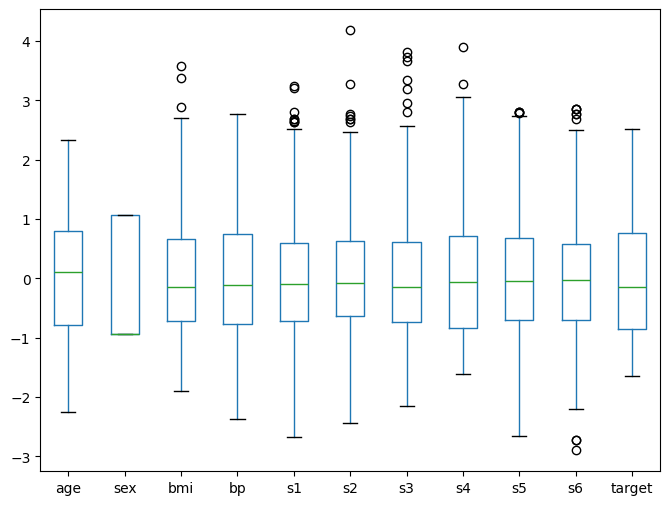

In [4]:
# DATA EXPLORATION
scaler = StandardScaler()     # standardizzo a causa delle diverse scale presenti tra features e target. Il target comprime le features
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

df_scaled.boxplot(figsize=(8, 6), grid=False)
plt.show()

# ottenuto il boxplot di tutte le fatures e del target.
# non ci sono outlier così estremi da essere eliminati

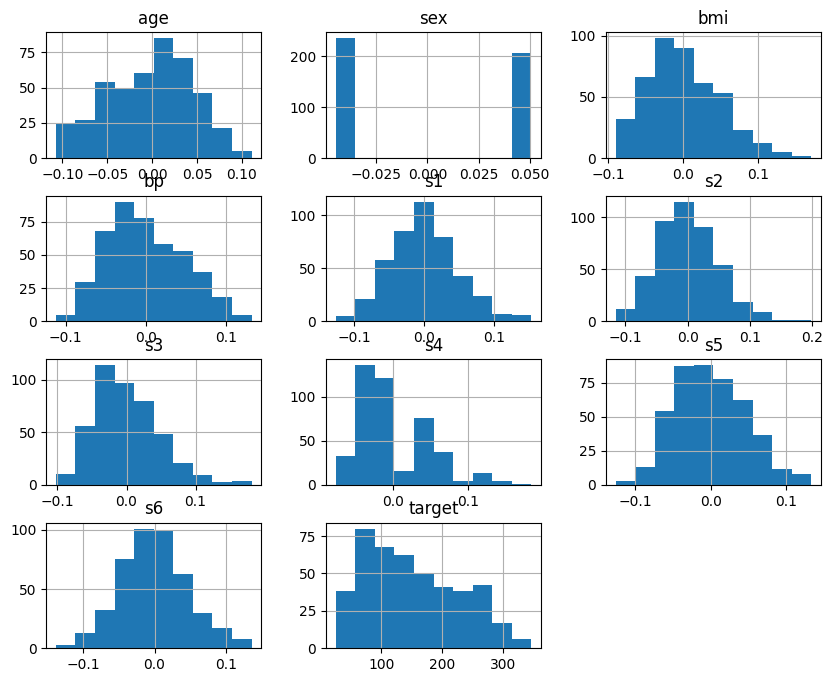

In [7]:
# istogramma
df.hist(figsize=(10, 8))
plt.show()

# abbiamo un istogramma per ogni features e per il target 
# la maggior parte delle feature ha una distribuzione approssimativamente normale/simmetrica.
# sex ha distribuzione binaria (due picchi netti)
# Il target è distribuito in modo quasi normale.

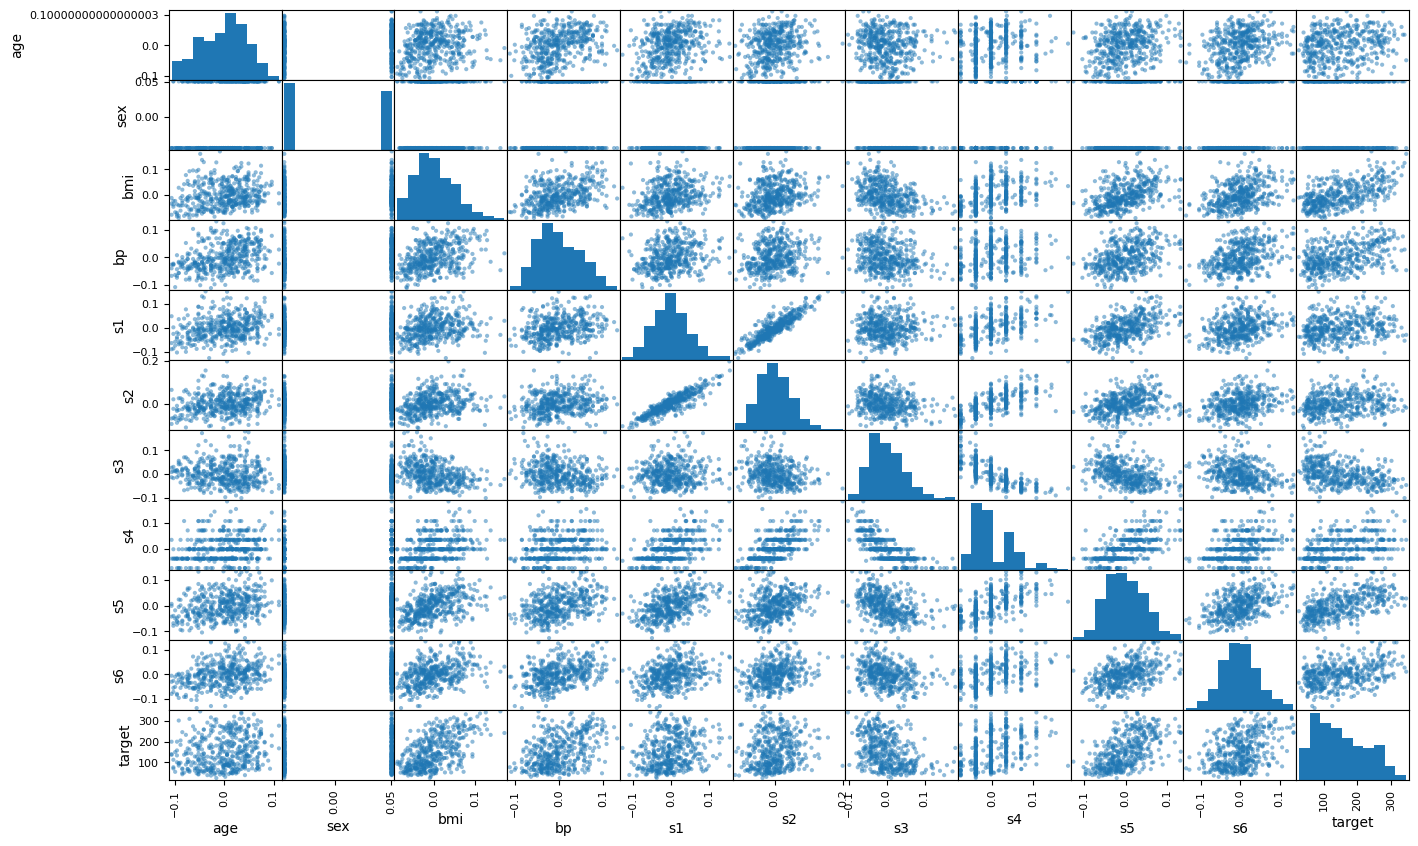

In [6]:
# scatter_matrix (mostra la relazione tra ogni coppia di variabili e la distribuzione di ogni singola variabile sulla diagonale)
scatter_matrix(df, figsize=(16, 10))
plt.show()

# bmi, bp (blood pressure) e s5 (log di trigliceridi) mostrano una correlazione più lineare col target rispetto ad altre feature

In [8]:
# dividiamo il dataset in train e test 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    shuffle=True,
    test_size=0.2,
    random_state=42
)

2. Confronto e selezione iniziale dei modelli

In [13]:
# selezione modelli di Regressione Standard
models = [
    ("SVM", SVR(kernel="rbf")),     # kernel = radial basis function per relazioni non lineari
    ("KNN", KNeighborsRegressor()),
    ("CART", DecisionTreeRegressor()),
    ("LR", LinearRegression()),
    ("LASSO", Lasso()),
    ("RIDGE", Ridge())
]

In [ ]:
# applicazione del K-Fold per individuare il modello più performante
names = []
results = []

K = 5    # valore ottimale per dataset grandi
for name, model in models:
    kfold = KFold(n_splits=K, shuffle=True, random_state=42)
    cv_results = cross_val_score(model, X_train, y_train, cv=kfold, scoring="neg_mean_squared_error")
    names.append(name)
    results.append(cv_results)
    print(f"{name}:\n\tMEAN:\t{cv_results.mean():.4f}\n\tSTD:\t{cv_results.std():.4f}")

# Linear Regression è il modello migliore perchè ha valori più bassi di MEAN e STD. 
# Infatti dai grafici precedenti abbiamo visto che molte features hanno relazione lineare con il target.
# la STD bassa significa che il modello generalizza bene.
# CART e SVM vanno in sofferenza
# RIDGE e LASSO sono versioni regolarizzate di LR e il fatto che performano leggermente peggio significa che la regolarizzazione non è necessaria sul dataset (feature già normalizzate)

SVM:
	MEAN:	-5364.2492
	STD:	794.0304
KNN:
	MEAN:	-3915.0892
	STD:	377.0980
CART:
	MEAN:	-6399.9111
	STD:	1552.8630
LR:
	MEAN:	-3074.1421
	STD:	265.1860
LASSO:
	MEAN:	-3956.7854
	STD:	558.4869
RIDGE:
	MEAN:	-3621.4959
	STD:	522.9666


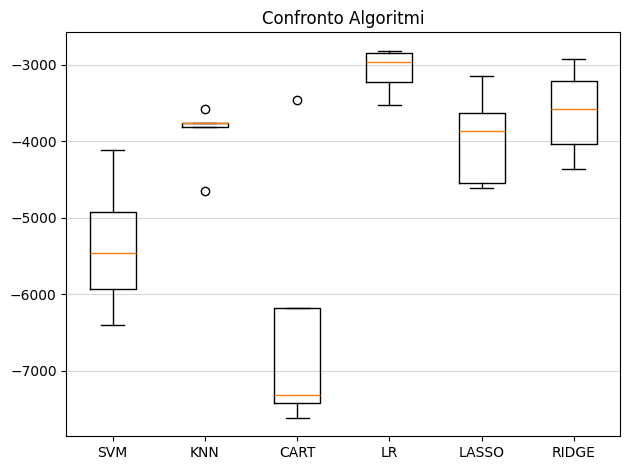

In [15]:
plt.boxplot(results, tick_labels=names)
plt.title("Confronto Algoritmi")
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [16]:
# modello allenato con l'algoritmo migliore
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [17]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:\t{mse:.3f}\nR2:\t{r2:.3f}")

# il modello non va in overfitting, MSE di test mostra un valore migliore sulla media sul set di training con cross-validation (3074)

MSE:	2900.194
R2:	0.453


3. Hyperparameters Tuning

In [18]:
# ottimizzare il modello con GridSearch solo su parametro alpha = controllo forza della regolarizzazione (cioè quanto il modello viene penalizzato per avere coeff. grandi)
# scelgo come algoritmo il RIDGE poichè la LinearRegression non ha iperparametri da ottimizzare.
# RIDGE ha ottenuto il secondo punteggio migliore dopo LinearRegression

param_grid = {
    "alpha": np.logspace(-3, 3, 7)
}

# provare tutti i valori di alpha e scegliere quello che ottiene miglior neg_mean_squarred_error
grid = GridSearchCV(
    cv=5,
    n_jobs=-1,
    estimator=Ridge(),   
    scoring="neg_mean_squared_error",   
    param_grid=param_grid
)
grid.fit(X_train, y_train)

print(f"Best alpha:\t{grid.best_params_["alpha"]}")
print(f"Best CV MSE:\t{grid.best_score_:.3f}")

best_model= grid.best_estimator_
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)


mse_best = mean_squared_error(y_test, y_pred_best)
r2_best  = r2_score(y_test, y_pred_best)
print(f"\nMSE:\t{mse_best:.3f}")
print(f"R2:\t{r2_best:.3f}")

# l'alpha migliore è 0.1 quindi il dataset non ha bisogno di regolarizzazione (feature già normalizzate). Ridge con 0.1 è quasi identico a LinearRegression
# a cui corrispnde una MSE e R2 ottimizzati rispetto a quelli della linear regression. 
# MSE migliora quindi Ridge generalizza un pò meglio sul Test set grazie alla regolarizzazione
# R2 dice che il modello spiega il 46% della varianza 

Best alpha:	0.1
Best CV MSE:	-3125.191

MSE:	2856.487
R2:	0.461


4. Analisi delle performance

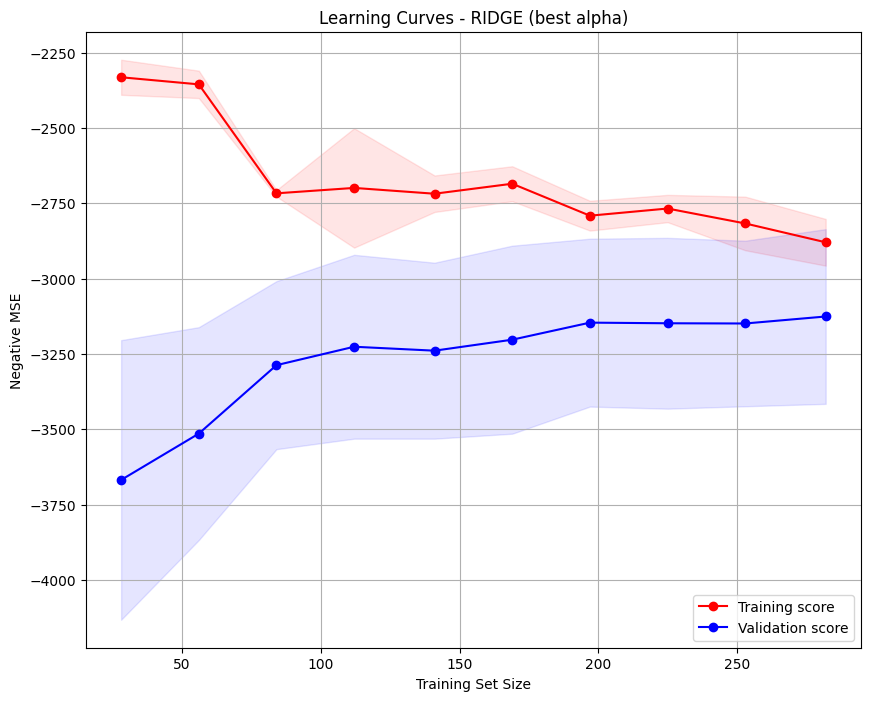

In [ ]:
# learning curves del modello ottimizzato
train_sizes, train_scores, val_scores = learning_curve(
    best_model,   # Ridge ottimizzato
    X_train,  # dati di addestramento
    y_train,
    cv=5,    # cross validation con 5 fold
    n_jobs=-1,   # usa tutti i core della CPU disponibili 
    scoring="neg_mean_squared_error",   # metrica usata
    train_sizes=np.linspace(0.1, 1.0, 10)  # genera 10 dimensioni del training set tra il 10% e il 100%
)

# calcolo delle medie per ogni dimesnione del training set e delle dev.std (misura quanto i risultati variano tra i vari fold)
train_mean = np.mean(train_scores, axis=1)      # axis=1 --> calcola la media lungo le colonne (fold) per ogni riga 
train_std= np.std(train_scores, axis=1)         
val_mean = np.mean(val_scores, axis=1)          
val_std = np.std(val_scores, axis=1)            

plt.figure(figsize=(10, 8))
plt.plot(train_sizes, train_mean, "o-", color="red", label="Training score")   # curva di training 
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="red")   # area colorata = media +- dev.std.
plt.plot(train_sizes, val_mean, "o-", color="blue", label="Validation score")  # curva di validazione
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color="blue")

plt.xlabel("Training Set Size")
plt.ylabel("Negative MSE")
plt.title("Learning Curves - RIDGE (best alpha)")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# - Se le due curve convergono verso valori vicini a 0 (poco negativi) --> il modello generalizza bene, basso bias
# - Se entrambe le curve sono molto negative e vicine tra loro --> underfitting (alto bias, il modello è troppo semplice)
# - Se la curva di training è molto migliore (più vicina a 0) di quella di validazione --> overfitting (alta varianza, il modello non generalizza)
# In questo caso le curve si avvicinano ma non arrivano vicino a 0 --> leggero underfitting/ alto bias --> 
# quindi il modello lineare generalizza abbastanza bene (piccolo gap tra training/validation) ma non riesce a catturare tutta la complessità del fenomeno

5. Visualizzazione con Data Reduction

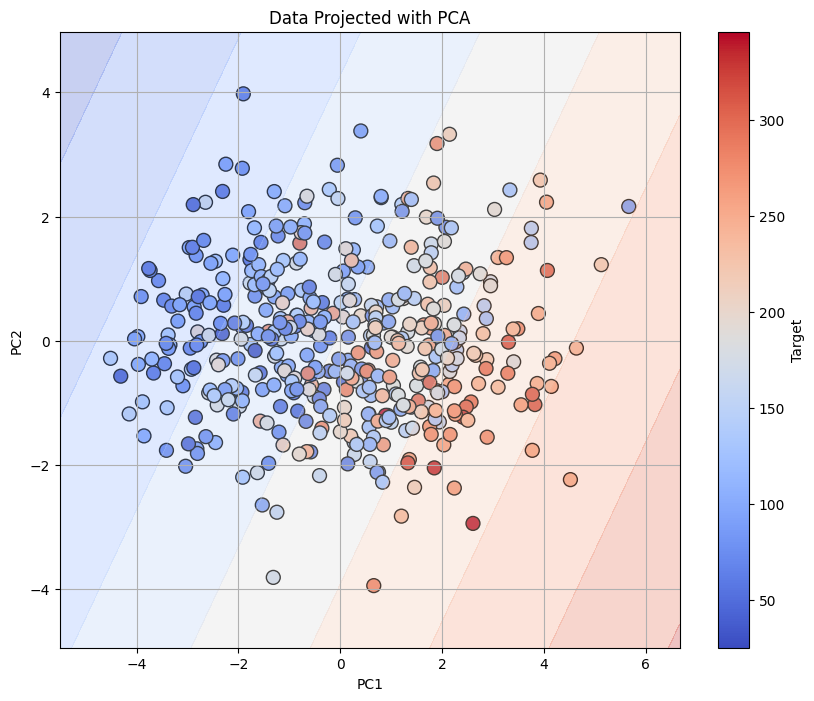

In [23]:
# rappresentazione grafica del modello in 2D con PCA
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X)

pca = PCA (n_components=2)
X_pca = pca.fit_transform(X_scaled)

best_model.fit(X_pca, y)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=100)

# creazione della griglia di dati equispaziati
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1    # 0.1 = margine per evitare di tagliare i bordi
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

# trasformazione dei due vettori in una griglia 2D con meshgrid
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))  # valori equispaziati di 300

# predizione della label a partire dalle coordinate individuate con la meshgrid ma appiattite con ravel che converte le matrici 2D in vettori 1D
Z = best_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  # reshape per riportare le coordinate nella forma originale (quindi da vettore 1D a matrice 2D)

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")   # conturf per colorare il decision boundary 

plt.title("Data Projected with PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, label="Target")
plt.grid(True)
plt.show()

